# Fisher y predicted bias: shift_stretch

Esta libreta usa exclusivamente `nz_model="shift_stretch"`, implementado en
`nz_shift_stretch.py`, con tus datos de `source_year1_outliers_OFF.npz`.
La PDF central es la plantilla; cada bin tiene dos parámetros libres:
desplazamiento `dz` y factor de anchura `stretch`.

$$n_i(z;\delta z_i,s_i)\propto\frac{1}{s_i}
n_i^{\rm central}\left(z_{p,i}+\frac{z-z_{p,i}-\delta z_i}{s_i}\right).$$

El pivote $z_{p,i}$ es la media central. Los fiduciales son $(\delta z_i,s_i)=(0,1)$:
la distribución fiducial conserva la forma central. El modelo interpola la plantilla
y normaliza en el intervalo de la malla.

`FisherFlex` estima el **prior desde `samples`**, sin una covarianza introducida
manualmente. `nz_truth` solo se usa después para predecir el bias.
Ejecuta las celdas en orden con el kernel `fisher_env`.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

from pathlib import Path
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import tables_io
import fisherA2Z.fisher_flex as ff

FisherFlex = ff.FisherFlex
plt.rcParams["figure.dpi"] = 110
%matplotlib inline

## Datos y selección de realizaciones

`MAX_REALIZATIONS = None` usa todas las realizaciones. Para una prueba rápida,
puedes poner `500`: selecciona los mismos índices, uniformemente espaciados,
en todos los bins. La PDF central siempre se calcula con el ensemble completo.

Usamos la malla nativa tanto para las PDFs centrales como para los samples.
Así se evita interpolar el ensemble completo a una malla mucho más grande.
La precisión numérica del forecast queda sujeta a esta resolución; interpolar
no añade información nueva a las PDFs originales.

In [2]:
REPO = Path(ff.__file__).resolve().parents[2]
EXAMPLE_DIR = REPO / "examples" / "nzdc_example"
DATA_FILE = REPO.parent / "yaw_bins" / "Results" / "source_year1_outliers_OFF.npz"
BHAT_FILE = EXAMPLE_DIR / "nz_challenge_taskset_1_cardinal_1yr_bhat_wfd.hdf5"
OUTPUT_DIR = EXAMPLE_DIR / "outputs_shift_stretch"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_REALIZATIONS = None  # Todas; usa 500, por ejemplo, para limitar el prior.
FORECAST_PARAMS = dict(ell_min_cs=300, ell_max_cs=1800)

with np.load(DATA_FILE) as data:
    z_grid = np.asarray(data["z_grid"], dtype=float)
    samples = np.asarray(data["samples"], dtype=float)
    nz_true = np.asarray(data["nz_truth"], dtype=float)

n_bins, n_available, n_z = samples.shape
if n_z != z_grid.size or nz_true.shape != (n_bins, n_z):
    raise ValueError("samples, nz_truth y z_grid deben compartir bins y malla.")

# Primero la media completa; después, la selección opcional para el prior.
nz_central = samples.mean(axis=1)
nz_central /= np.trapz(nz_central, z_grid, axis=1)[:, None]
nz_true /= np.trapz(nz_true, z_grid, axis=1)[:, None]
if MAX_REALIZATIONS is not None:
    if not isinstance(MAX_REALIZATIONS, int) or isinstance(MAX_REALIZATIONS, bool) or MAX_REALIZATIONS < 3:
        raise ValueError("MAX_REALIZATIONS debe ser None o un entero >= 3.")
    indices = np.linspace(0, n_available - 1, min(MAX_REALIZATIONS, n_available), dtype=int)
    samples = samples[:, indices, :]
n_used = samples.shape[1]
FISHER_FILE = OUTPUT_DIR / f"fisher_{DATA_FILE.stem}_shift_stretch_{n_used}samples.npz"

print("Archivo:", DATA_FILE.name)
print(f"Bins: {n_bins} | nodos de redshift: {n_z}")
print(f"Realizaciones para el prior: {n_used}/{n_available} por bin")
print("Forma de samples:", samples.shape)

Archivo: source_year1_outliers_OFF.npz
Bins: 5 | nodos de redshift: 40
Realizaciones para el prior: 199499/199499 por bin
Forma de samples: (5, 199499, 40)


## Densidad efectiva

Se conserva la densidad Cardinal 1yr usada en las otras libretas. Proviene del
catálogo HDF5, **no de las PDFs del NPZ**. Para una interpretación física del
forecast, esta densidad debe corresponder a la selección de galaxias de tus n(z).

In [3]:
N_CATALOG = 3_505_864
N_SAMPLED = 1_000_000
AREA_ARCMIN2 = 107.4295 * 3600

bhat_table = tables_io.read(str(BHAT_FILE))
counts = np.bincount(bhat_table["bhat_for_wide_data"], minlength=n_bins)[:n_bins]
neff = counts * (N_CATALOG / AREA_ARCMIN2) / N_SAMPLED
print("Conteos por bin:", counts)
print("neff [gal/arcmin²]:", neff)

Conteos por bin: [196661 196375 189284 214686 202994]
neff [gal/arcmin²]: [1.7827369  1.7801443  1.71586421 1.94613397 1.8401457 ]


## Modelo y prior automático desde samples

Para cada realización $r$ y bin $i$, el código mide:

$$\delta z_i^{(r)}=\langle z\rangle_i^{(r)}-\langle z\rangle_i^{\rm central},
\qquad s_i^{(r)}=\sigma_i^{(r)}/\sigma_i^{\rm central}.$$

Calcula la covarianza muestral de estos dos parámetros por bin. `prior_mode="full"`
conserva su correlación dentro de cada bin; no añade correlaciones entre bins.
No divide la covarianza entre el número de realizaciones.

Estos son estimadores por momentos, sin optimizador. Si una realización tiene
cambios de forma más complejos, el modelo solo recoge su desplazamiento y anchura.
El prior del forecast se centra en los fiduciales `(0, 1)`; la media de los
parámetros del ensemble que imprimimos es un diagnóstico y no cambia esos fiduciales.

In [4]:
flex = FisherFlex(
    nz_source=nz_central,
    nz_realizations=samples,  # El prior se mide aquí a partir de las realizaciones.
    realizations_axis=1,      # samples tiene forma (bin, realización, redshift).
    z_grid=z_grid,
    neff_source=neff,
    fsky=0.5,
    sigma_e=0.26,
    mode="cosmic_shear",
    nz_model="shift_stretch",
    prior_mode="full",
    deriv_method="central",
)

print("Fiduciales por bin: dz = 0, stretch = 1")
print("Parámetros foto-z libres:", n_bins * flex.n_pz_per_bin)
print("Forma del prior calculado:", flex.pz_prior_cov.shape)
print("Media del ensemble [dz, stretch]:\n", flex.realization_params.mean(axis=0))
print("Desviaciones del prior [sigma(dz), sigma(stretch)]:\n",
      np.sqrt(np.diagonal(flex.pz_prior_cov, axis1=1, axis2=2)))
del samples  # Las realizaciones ya se han convertido en parámetros y covarianzas.

Measuring the shift and stretch of 199499 realizations ...


Fiduciales por bin: dz = 0, stretch = 1
Parámetros foto-z libres: 10
Forma del prior calculado: (5, 2, 2)
Media del ensemble [dz, stretch]:
 [[ 9.99607343e-05  1.00018437e+00]
 [-7.73429806e-04  9.98756252e-01]
 [-6.65716031e-04  9.98793194e-01]
 [-9.77973578e-03  9.66758153e-01]
 [ 7.00748922e-05  9.92975400e-01]]
Desviaciones del prior [sigma(dz), sigma(stretch)]:
 [[0.02062728 0.01700662]
 [0.03091328 0.02002855]
 [0.02835046 0.02213331]
 [0.09465328 0.17243757]
 [0.06015668 0.0457585 ]]


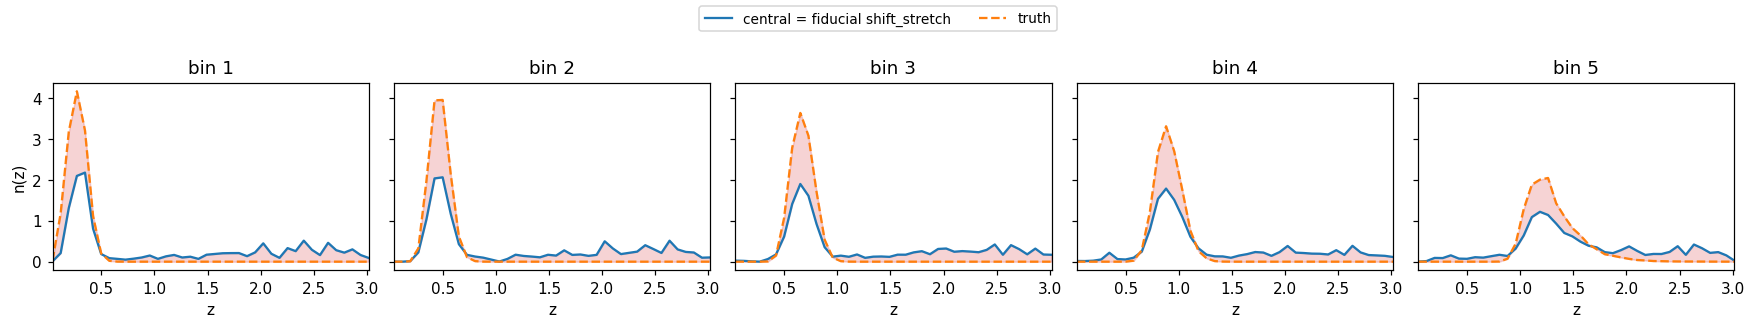

In [5]:
fig, axes = plt.subplots(1, n_bins, figsize=(16, 3), sharey=True, squeeze=False)
for b, ax in enumerate(axes[0]):
    ax.plot(z_grid, flex.nz_source_fid[b], color="C0",
            label="central = fiducial shift_stretch" if b == 0 else None)
    ax.plot(z_grid, nz_true[b], "--", color="C1", label="truth" if b == 0 else None)
    ax.fill_between(z_grid, flex.nz_source_fid[b], nz_true[b], color="C3", alpha=0.2)
    ax.set(title=f"bin {b+1}", xlabel="z", xlim=(z_grid[0], z_grid[-1]))
axes[0, 0].set_ylabel("n(z)")
fig.legend(loc="upper center", ncol=2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.savefig(OUTPUT_DIR / "nz_shift_stretch.png", dpi=160, bbox_inches="tight")
plt.show()

## Forecast

`compute()` calcula los espectros, sus derivadas y la covarianza. Es obligatorio
ejecutarlo antes de `forecast()`, que aplica los cortes y marginaliza los
parámetros libres. Se recalculan las derivadas para este modelo.
Los priors cosmológicos y de alineamiento intrínseco conservan los valores
predeterminados de FisherFlex; el prior foto-z procede de samples.

In [6]:
flex.compute(parallel=True, n_proc=2, save=str(FISHER_FILE))
res = flex.forecast(**FORECAST_PARAMS)
np.linalg.cholesky((res.cov + res.cov.T) / 2)

s8, s8_err = res.s8()
print(f"Cosmic shear, shift_stretch: S_8 = {s8:.4f} +/- {s8_err:.4f}")
print(f"FoM(w0,wa) = {res.fom('w_0', 'w_a'):.2f}")
print("Resultados:", FISHER_FILE)

Computing the fiducial data vector and covariance ...


Computing derivatives for 31 parameters (parallel) ...


Done.


Saved to /home/davidmarquez/photometric_redshifts_project/fisherA2Z/examples/nzdc_example/outputs_shift_stretch/fisher_source_year1_outliers_OFF_shift_stretch_199499samples.npz


Cosmic shear, shift_stretch: S_8 = 0.8523 +/- 0.0127
FoM(w0,wa) = 8.93
Resultados: /home/davidmarquez/photometric_redshifts_project/fisherA2Z/examples/nzdc_example/outputs_shift_stretch/fisher_source_year1_outliers_OFF_shift_stretch_199499samples.npz


## Predicted bias

Ahora se utiliza `nz_truth` para calcular el cambio de los espectros respecto
al fiducial y predecir el desplazamiento de los parámetros:

$$\Delta\theta=F^{-1}J^T\,\mathrm{Cov}^{-1}(C^{\rm truth}-C^{\rm fid}).$$

Se usan los mismos cortes y priors del forecast. Es una aproximación local de
primer orden; desplazamientos grandes requieren comprobar su validez.

In [7]:
bias = flex.forecast_bias(nz_truth=nz_true, forecast_params=FORECAST_PARAMS)
COSMO_PARAMS = ["omega_m", "sigma_8", "w_0", "w_a"]
print(bias.summary(COSMO_PARAMS))
if bias.shifted_fid("omega_m") > 0 and bias.shifted_fid("sigma_8") > 0:
    s8_fid, s8_shifted, ds8, ds8_sigma = bias.s8()
    print(f"\nS_8: {s8_fid:.4f} -> {s8_shifted:.4f} ({ds8:+.4f}, {ds8_sigma:+.2f} sigma)")
else:
    print("\nNo se calcula S_8 desplazado: el bias lineal sale del dominio físico.")
print(f"Residuo fraccional medio de los espectros (MAFE): {bias.mafe():.2%}")

parameter         fiducial        bias  bias/sigma     shifted
omega_m             0.3156    0.049809       4.407     0.36541
sigma_8              0.831   -0.084249      -6.097     0.74675
w_0                     -1     -2.1209     -12.904     -3.1209
w_a                      0      10.667      12.834      10.667

S_8: 0.8523 -> 0.8241 (-0.0282, -2.23 sigma)
Residuo fraccional medio de los espectros (MAFE): 54.26%


## Bias en dos dimensiones

`bias_2d` compara el desplazamiento con la covarianza conjunta del par,
marginalizando todos los demás parámetros.

In [8]:
PARAMETER_PAIRS = [("omega_m", "sigma_8"), ("w_0", "w_a")]
for pair in PARAMETER_PAIRS:
    print(bias.bias_2d(*pair))
    print()

bias in the (omega_m, sigma_8) plane
  omega_m           0.3156 ->     0.36541   (+4.41 sigma_1D)
  sigma_8            0.831 ->     0.74675   (-6.10 sigma_1D)
  joint: chi2 = 37.688, sqrt(chi2) = 6.14, enclosing 100.0% of the posterior
  direction: -59.4 deg;  inside 1 sigma: False;  inside 2 sigma: False

bias in the (w_0, w_a) plane
  w_0                   -1 ->     -3.1209   (-12.90 sigma_1D)
  w_a                    0 ->      10.667   (+12.83 sigma_1D)
  joint: chi2 = 210.650, sqrt(chi2) = 14.51, enclosing 100.0% of the posterior
  direction: +101.2 deg;  inside 1 sigma: False;  inside 2 sigma: False



## Corner + arrows

Azul: forecast fiducial. Naranja: bias predicho y contorno trasladado.
El contorno naranja conserva la covarianza fiducial; no es un nuevo forecast
calculado en el punto desplazado. Los límites incluyen ambos centros.

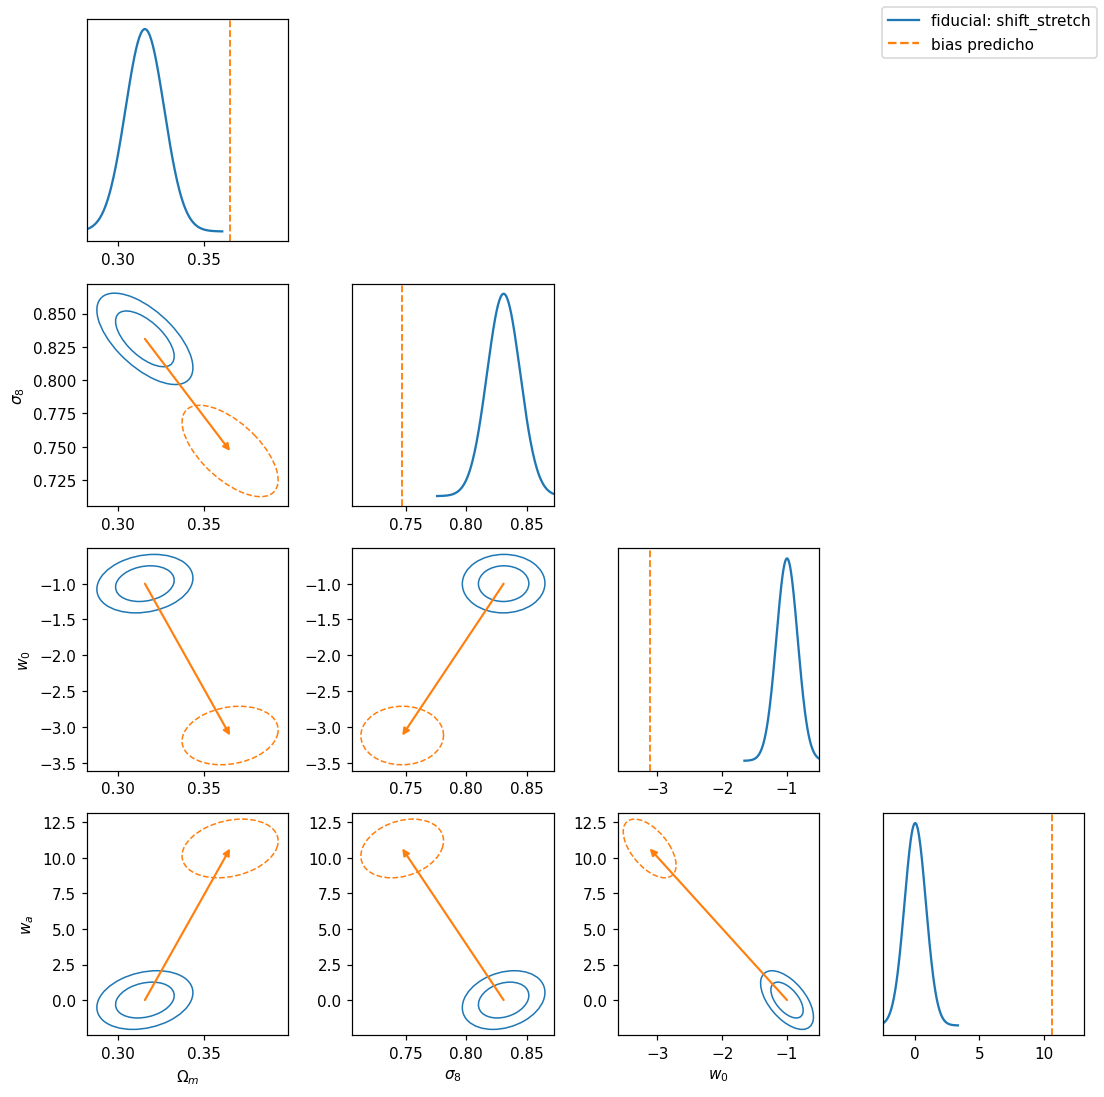

In [9]:
def limits_with_bias(parameter):
    centers = (res.param_fid[parameter], bias.shifted_fid(parameter))
    margin = 3.0 * res.sigma(parameter)
    return min(centers) - margin, max(centers) + margin

legend_handles = [
    Line2D([], [], color="C0", label="fiducial: shift_stretch"),
    Line2D([], [], color="C1", ls="--", label="bias predicho"),
]
fig = res.corner(COSMO_PARAMS, color="C0", label="shift_stretch", figsize=(10, 10))
bias.corner_arrows(COSMO_PARAMS, fig=fig, shifted_contour=True, color="C1")
axes = np.asarray(fig.axes).reshape(len(COSMO_PARAMS), len(COSMO_PARAMS))
for row, p_y in enumerate(COSMO_PARAMS):
    for col, p_x in enumerate(COSMO_PARAMS[:row + 1]):
        axes[row, col].set_xlim(limits_with_bias(p_x))
        if row != col:
            axes[row, col].set_ylim(limits_with_bias(p_y))
fig.legend(handles=legend_handles, loc="upper right", fontsize=10)
fig.savefig(OUTPUT_DIR / "corner_shift_stretch_bias.png", dpi=160, bbox_inches="tight")
plt.show()

## Contornos + flechas

Los contornos azules son las regiones conjuntas de 68.3% y 95.4%.
El contorno naranja discontinuo es la región de 95.4% trasladada por el bias.
La confianza indicada en el título corresponde a la elipse que alcanza el
desplazamiento predicho, no a la probabilidad de que el modelo sea correcto.

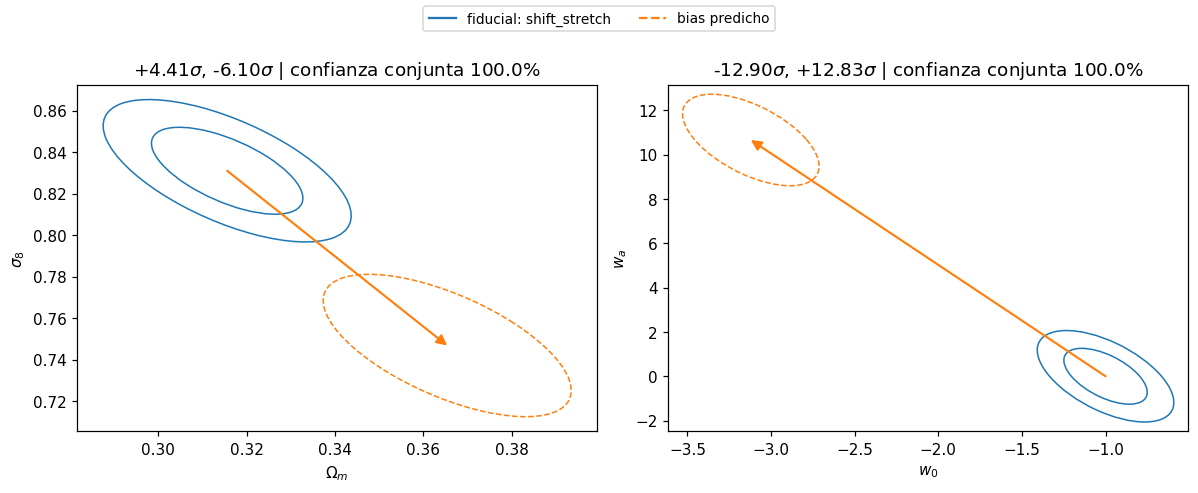

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (p1, p2) in zip(axes, PARAMETER_PAIRS):
    res.contour(p1, p2, ax=ax, color="C0")
    bias.arrow(p1, p2, ax=ax, shifted_contour=True, color="C1")
    joint = bias.bias_2d(p1, p2)
    ax.set_xlim(limits_with_bias(p1))
    ax.set_ylim(limits_with_bias(p2))
    ax.set_title(
        rf"{bias.n_sigma(p1):+.2f}$\sigma$, {bias.n_sigma(p2):+.2f}$\sigma$"
        f" | confianza conjunta {joint.confidence:.1%}"
    )
fig.legend(handles=legend_handles, loc="upper center", ncol=2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(OUTPUT_DIR / "contours_shift_stretch_bias.png", dpi=160, bbox_inches="tight")
plt.show()